In [1]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import math
import scipy.stats as stats
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report
import datetime
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

#Load data
teams = pd.read_csv('data/clean_teams.csv')

teams

,Unnamed: 0,year,tmID,confID,playoff,firstRound,semis,finals,o_fgm,o_fga,...,won,lost,GP,homeW,homeL,awayW,awayL,confW,confL,min
0,0,9,ATL,EA,N,NaN,NaN,NaN,895,2258,...,4,30,34,1,16,3,14,2,18,6825
1,1,10,ATL,EA,Y,L,NaN,NaN,1089,2428,...,18,16,34,12,5,6,11,10,12,6950
2,2,1,CHA,EA,N,NaN,NaN,NaN,812,1903,...,8,24,32,5,11,3,13,5,16,6475
3,3,2,CHA,EA,Y,W,W,L,746,1780,...,18,14,32,11,5,7,9,15,6,6500
4,4,3,CHA,EA,Y,L,NaN,NaN,770,1790,...,18,14,32,11,5,7,9,12,9,6450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,EA,N,NaN,NaN,NaN,847,1968,...,16,18,34,10,7,6,11,9,11,6900
138,138,7,WAS,EA,Y,L,NaN,NaN,1016,2199,...,18,16,34,13,4,5,12,12,8,6850
139,139,8,WAS,EA,N,NaN,NaN,NaN,877,2170,...,16,18,34,8,9,8,9,8,12,6900
140,140,9,WAS,EA,N,NaN,NaN,NaN,885,2131,...,10,24,34,6,11,4,13,6,14,6825


In [2]:
teams['playoff'] = (teams['playoff'] == 'Y').astype(int)

teams['firstRound'] = teams['firstRound'].fillna(0)
teams['firstRound'] = teams['firstRound'].replace('W',1)
teams['firstRound'] = teams['firstRound'].replace('L',1)

teams['semis'] = teams['semis'].fillna(0)
teams['semis'] = teams['semis'].replace('W',1)
teams['semis'] = teams['semis'].replace('L',1)

teams['finals'] = teams['finals'].fillna(0)
teams['finals'] = teams['finals'].replace('W',2)
teams['finals'] = teams['finals'].replace('L',1)

teams['playoff_result'] = teams['firstRound'] + teams['semis'] + teams['finals']

teams = teams.drop(['firstRound','semis','finals'], axis=1)

teams['east'] = (teams['confID'] == 'EA').astype(int)
teams['west'] = (teams['confID'] == 'WE').astype(int)

teams.drop('confID', axis=1, inplace=True)

teams

,Unnamed: 0,year,tmID,playoff,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,...,homeW,homeL,awayW,awayL,confW,confL,min,playoff_result,east,west
0,0,9,ATL,0,895,2258,542,725,202,598,...,1,16,3,14,2,18,6825,0,1,0
1,1,10,ATL,1,1089,2428,569,755,114,374,...,12,5,6,11,10,12,6950,1,1,0
2,2,1,CHA,0,812,1903,431,577,131,386,...,5,11,3,13,5,16,6475,0,1,0
3,3,2,CHA,1,746,1780,410,528,153,428,...,11,5,7,9,15,6,6500,3,1,0
4,4,3,CHA,1,770,1790,490,663,211,527,...,11,5,7,9,12,9,6450,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,0,847,1968,388,546,181,510,...,10,7,6,11,9,11,6900,0,1,0
138,138,7,WAS,1,1016,2199,528,715,187,522,...,13,4,5,12,12,8,6850,1,1,0
139,139,8,WAS,0,877,2170,668,839,163,528,...,8,9,8,9,8,12,6900,0,1,0
140,140,9,WAS,0,885,2131,435,659,163,460,...,6,11,4,13,6,14,6825,0,1,0


In [3]:
teams['win_ratio'] = teams['won'] / teams['GP']
teams['win_ratio'] = teams['win_ratio'].apply(lambda x: round(x, 2))

teams.drop(['won','lost', 'GP'], axis=1, inplace=True)

teams

,Unnamed: 0,year,tmID,playoff,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,...,homeL,awayW,awayL,confW,confL,min,playoff_result,east,west,win_ratio
0,0,9,ATL,0,895,2258,542,725,202,598,...,16,3,14,2,18,6825,0,1,0,0.12
1,1,10,ATL,1,1089,2428,569,755,114,374,...,5,6,11,10,12,6950,1,1,0,0.53
2,2,1,CHA,0,812,1903,431,577,131,386,...,11,3,13,5,16,6475,0,1,0,0.25
3,3,2,CHA,1,746,1780,410,528,153,428,...,5,7,9,15,6,6500,3,1,0,0.56
4,4,3,CHA,1,770,1790,490,663,211,527,...,5,7,9,12,9,6450,1,1,0,0.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,0,847,1968,388,546,181,510,...,7,6,11,9,11,6900,0,1,0,0.47
138,138,7,WAS,1,1016,2199,528,715,187,522,...,4,5,12,12,8,6850,1,1,0,0.53
139,139,8,WAS,0,877,2170,668,839,163,528,...,9,8,9,8,12,6900,0,1,0,0.47
140,140,9,WAS,0,885,2131,435,659,163,460,...,11,4,13,6,14,6825,0,1,0,0.29


In [4]:
#Possessions = Team Possessions = 0.5 * ((Team FGA + 0.4 * Team FTA - 1.07 * (Team OREB / (Team OREB + Opponent DREB)) * (Team FGA - Team FG) + Team TO) + (Opponent FGA + 0.4 * Opponent FTA - 1.07 * (Opponent OREB / (Opponent OREB + Team DREB)) * (Opponent FGA - Opponent FG) + Opponent TO))
teams['possesions'] = 0.5 * (teams['o_fga'] + 0.4 * teams['o_fta'] - 1.07 * (teams['o_oreb'] / (teams['o_oreb'] + teams['d_dreb'])) * (teams['o_fga'] - teams['o_fgm']) + teams['o_to']+
                             teams['d_fga'] + 0.4 * teams['d_fta'] - 1.07 * (teams['d_oreb'] / (teams['d_oreb'] + teams['o_dreb'])) * (teams['d_fga'] - teams['d_fgm']) + teams['d_to'])

In [5]:
#OFF EFF = 100 x (Points / Possessions)
teams['off_rtg'] = 100 * (teams['o_pts'] / teams['possesions'])
teams['off_rtg'] = teams['off_rtg'].apply(lambda x: round(x, 1))

#DEF EFF = 100 x (Opponent Points / Opponent Possessions)
teams['def_rtg'] = 100 * (teams['d_pts'] / teams['possesions'])
teams['def_rtg'] = teams['def_rtg'].apply(lambda x: round(x, 1))

# NET EFF = OFF EFF - DEF EFF
teams['net_rtg'] = teams['off_rtg'] - teams['def_rtg']
teams['net_rtg'] = teams['net_rtg'].apply(lambda x: round(x, 1))

teams.drop(['possesions', 'off_rtg', 'def_rtg'], axis=1, inplace=True)
teams.head()

,Unnamed: 0,year,tmID,playoff,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,...,awayW,awayL,confW,confL,min,playoff_result,east,west,win_ratio,net_rtg
0,0,9,ATL,0,895,2258,542,725,202,598,...,3,14,2,18,6825,0,1,0,0.12,-12.7
1,1,10,ATL,1,1089,2428,569,755,114,374,...,6,11,10,12,6950,1,1,0,0.53,2.3
2,2,1,CHA,0,812,1903,431,577,131,386,...,3,13,5,16,6475,0,1,0,0.25,-10.7
3,3,2,CHA,1,746,1780,410,528,153,428,...,7,9,15,6,6500,3,1,0,0.56,2.2
4,4,3,CHA,1,770,1790,490,663,211,527,...,7,9,12,9,6450,1,1,0,0.56,5.1


In [6]:
teams.drop(["o_fgm", "o_fga", "o_ftm", "o_fta", "o_3pm", "o_3pa", "o_oreb", "o_dreb", "o_reb", "o_asts", "o_pf", "o_stl", "o_to", "o_blk", "o_pts"], axis=1, inplace=True)
teams.drop(["d_fgm", "d_fga", "d_ftm", "d_fta", "d_3pm", "d_3pa", "d_oreb", "d_dreb", "d_reb", "d_asts", "d_pf", "d_stl", "d_to", "d_blk", "d_pts", "homeW", "homeL", "awayW", "awayL"], axis=1, inplace=True)
teams.head()

,Unnamed: 0,year,tmID,playoff,confW,confL,min,playoff_result,east,west,win_ratio,net_rtg
0,0,9,ATL,0,2,18,6825,0,1,0,0.12,-12.7
1,1,10,ATL,1,10,12,6950,1,1,0,0.53,2.3
2,2,1,CHA,0,5,16,6475,0,1,0,0.25,-10.7
3,3,2,CHA,1,15,6,6500,3,1,0,0.56,2.2
4,4,3,CHA,1,12,9,6450,1,1,0,0.56,5.1


In [7]:
teams['next_year'] = teams['year'] + 1

# select some columns for getting previous year data
teams2 = teams[['next_year','tmID', 'playoff_result','net_rtg','win_ratio']]

# join teams and teams2
teams = teams.merge(teams2, left_on=['year','tmID'], right_on=['next_year','tmID'], suffixes=('','_previous'))

teams = teams.drop(['next_year_previous'], axis=1)

teams

,Unnamed: 0,year,tmID,playoff,confW,confL,min,playoff_result,east,west,win_ratio,net_rtg,next_year,playoff_result_previous,net_rtg_previous,win_ratio_previous
0,1,10,ATL,1,10,12,6950,1,1,0,0.53,2.3,11,0,-12.7,0.12
1,3,2,CHA,1,15,6,6500,3,1,0,0.56,2.2,3,0,-10.7,0.25
2,4,3,CHA,1,12,9,6450,1,1,0,0.56,5.1,4,3,2.2,0.56
3,5,4,CHA,1,12,12,6850,1,1,0,0.53,1.0,5,1,5.1,0.56
4,6,5,CHA,0,8,12,6900,0,1,0,0.47,-3.5,6,1,1.0,0.53
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117,137,6,WAS,0,9,11,6900,0,1,0,0.47,-1.9,7,1,-2.4,0.50
118,138,7,WAS,1,12,8,6850,1,1,0,0.53,3.4,8,0,-1.9,0.47
119,139,8,WAS,0,8,12,6900,0,1,0,0.47,-2.1,9,1,3.4,0.53
120,140,9,WAS,0,6,14,6825,0,1,0,0.29,-9.0,10,0,-2.1,0.47


<Axes: >

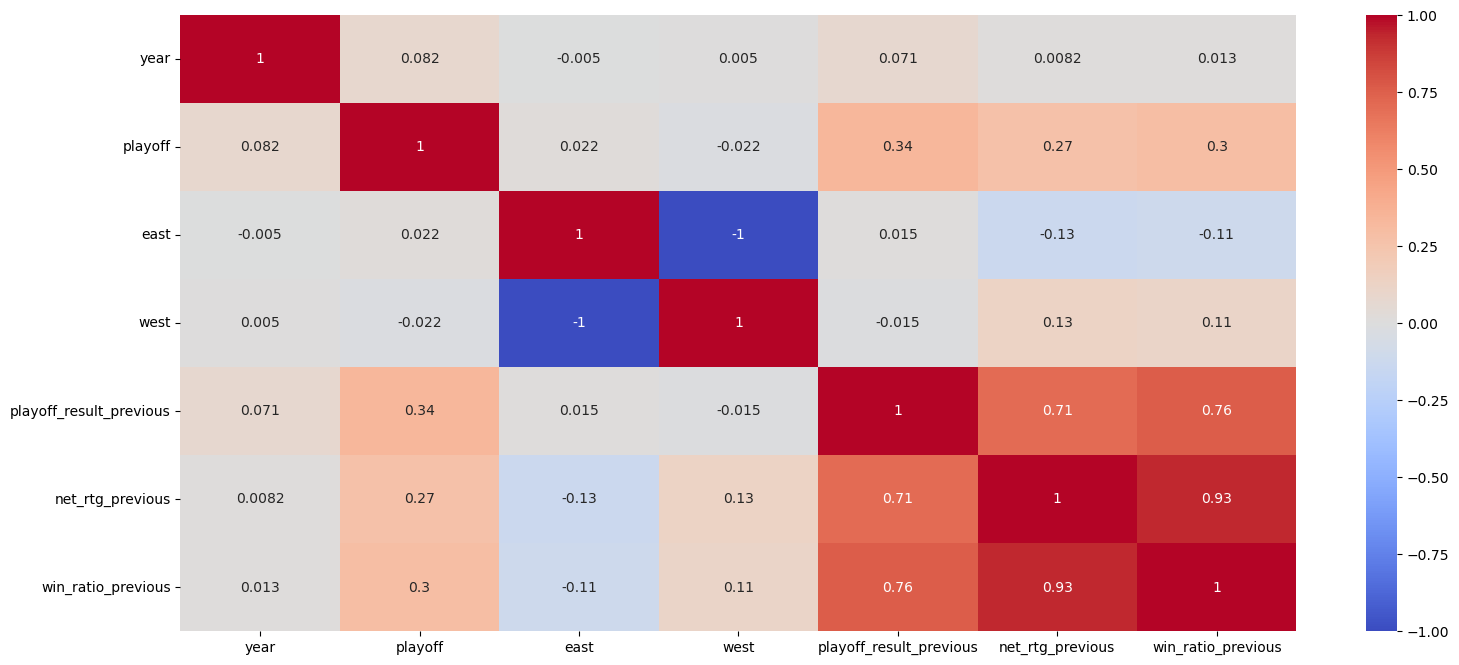

In [8]:
teams = teams[['year','playoff','east','west','playoff_result_previous','net_rtg_previous','win_ratio_previous']]

plt.figure(figsize=(18,8))
correlation = teams.corr()
sb.heatmap(correlation,annot=True,cmap='coolwarm')

In [15]:
players_teams_data = pd.read_csv("data/players_teams.csv")

In [16]:
# delete players who haven't played
players_teams_data = players_teams_data[players_teams_data['minutes'] != 0]

players_teams_data['UE'] = (players_teams_data['fgAttempted'] + 0.44 * players_teams_data['ftAttempted'] + players_teams_data['turnovers']) * 100 / players_teams_data['minutes']

In [12]:
players_teams_data['UE'] = players_teams_data['UE'].apply(lambda x: round(x, 1))

# Display the players team table with ORTG
players_teams_data[['playerID', 'year', 'UE']]

,playerID,year,ORTG
0,abrossv01w,2,117.1
1,abrossv01w,3,99.4
2,abrossv01w,4,111.6
3,abrossv01w,5,105.0
4,abrossv01w,6,110.1
...,...,...,...
1871,zakalok01w,3,100.0
1872,zarafr01w,6,105.9
1873,zellosh01w,10,136.7
1874,zirkozu01w,4,275.0


In [17]:
players_teams_data.drop(["fgAttempted", "fgAttempted", "turnovers", "minutes"], axis=1, inplace=True)
players_teams_data

,playerID,year,stint,tmID,lgID,GP,GS,points,oRebounds,dRebounds,...,PostTurnovers,PostPF,PostfgAttempted,PostfgMade,PostftAttempted,PostftMade,PostthreeAttempted,PostthreeMade,PostDQ,UE
0,abrossv01w,2,0,MIN,WNBA,26,23,343,43,131,...,0,0,0,0,0,0,0,0,0,51.546099
1,abrossv01w,3,0,MIN,WNBA,27,27,314,45,101,...,0,0,0,0,0,0,0,0,0,57.023602
2,abrossv01w,4,0,MIN,WNBA,30,25,318,44,97,...,8,8,22,6,8,8,7,3,0,52.792929
3,abrossv01w,5,0,MIN,WNBA,22,11,146,17,57,...,3,7,23,8,4,2,8,2,0,43.774892
4,abrossv01w,6,0,MIN,WNBA,31,31,304,29,78,...,0,0,0,0,0,0,0,0,0,49.951094
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1871,zakalok01w,3,2,PHO,WNBA,5,0,6,0,3,...,0,0,0,0,0,0,0,0,0,31.783784
1872,zarafr01w,6,0,SEA,WNBA,34,4,90,11,28,...,5,0,6,4,2,2,1,1,0,32.745763
1873,zellosh01w,10,0,DET,WNBA,34,4,406,25,81,...,7,15,68,24,27,23,17,7,0,56.563591
1874,zirkozu01w,4,0,WAS,WNBA,6,0,11,0,2,...,0,0,0,0,0,0,0,0,0,28.800000


# Testing models

In [399]:
def showResults(y_test, predictions, model,collumns,save):
    # Calculate and print the confusion matrix
    cm = confusion_matrix(y_test, predictions)

    filename = model

    # Plot the confusion matrix
    plt.figure(figsize=(5, 5))
    sb.heatmap(cm, annot=True, fmt='d', cmap='Greens')
    plt.title('Confusion matrix')
    plt.ylabel('Actual label')
    plt.xlabel('Predicted label')
    plt.show()

    # Print the classification report
    report = classification_report(y_test, predictions)

    print("Classification Report:\n", report)

In [370]:
teams.dropna(inplace=True)

# select only a few columns
new_df = teams[['year','playoff','east','west', 'playoff_result_previous','net_rtg_previous','win_ratio_previous']]

new_df

C:\Users\Catarina\AppData\Local\Temp\ipykernel_28332\2978715231.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  teams.dropna(inplace=True)


,year,playoff,east,west,playoff_result_previous,net_rtg_previous,win_ratio_previous
0,10,1,1,0,0,-12.7,0.12
1,2,1,1,0,0,-10.7,0.25
2,3,1,1,0,3,2.2,0.56
3,4,1,1,0,1,5.1,0.56
4,5,0,1,0,1,1.0,0.53
...,...,...,...,...,...,...,...
117,6,0,1,0,1,-2.4,0.50
118,7,1,1,0,0,-1.9,0.47
119,8,0,1,0,1,3.4,0.53
120,9,0,1,0,0,-2.1,0.47


In [371]:
# drop the tmID, year, made_playoffs column
X = new_df.drop(['year', 'playoff'], axis=1).values
y = new_df['playoff']

# Get the column names
column_names = new_df.drop(['year', 'playoff'], axis=1).columns.tolist()

# Time-based split
train_end_year = 7
test_start_year = 8

train_mask = new_df['year'] <= train_end_year
test_mask = new_df['year'] >= test_start_year

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

save_logs = False

Random Forest

Accuracy of the Random Forest model: 0.48717948717948717


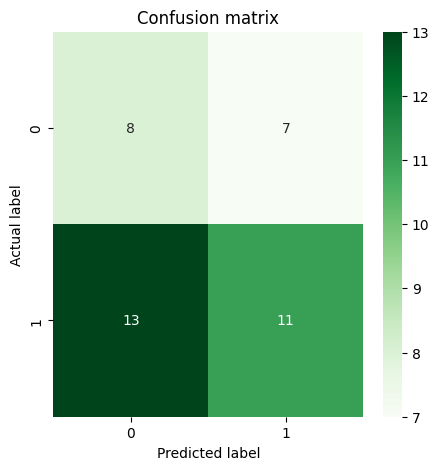

Classification Report:
               precision    recall  f1-score   support

           0       0.38      0.53      0.44        15
           1       0.61      0.46      0.52        24

    accuracy                           0.49        39
   macro avg       0.50      0.50      0.48        39
weighted avg       0.52      0.49      0.49        39



In [400]:
# Train the model
model = RandomForestClassifier(n_estimators=200,random_state=42)
model.fit(X_train, y_train)

# Make predictions
predictions_rm = model.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_rm)
print(f"Accuracy of the Random Forest model: {accuracy}")

showResults(y_test, predictions_rm,"random_forest",column_names,save_logs)

k-Nearest Neighbors (k-NN)

Accuracy of the k-NN model: 0.5897435897435898


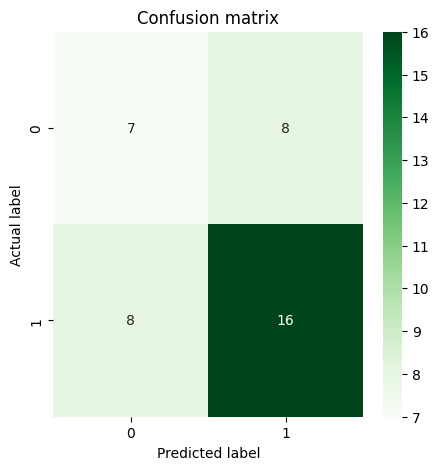

Classification Report:
               precision    recall  f1-score   support

           0       0.47      0.47      0.47        15
           1       0.67      0.67      0.67        24

    accuracy                           0.59        39
   macro avg       0.57      0.57      0.57        39
weighted avg       0.59      0.59      0.59        39



In [373]:
# Train the model
model_knn = KNeighborsClassifier(n_neighbors=5)  # the desired number of neighbors (k)
model_knn.fit(X_train, y_train)

# Make predictions
predictions_knn = model_knn.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_knn)
print(f"Accuracy of the k-NN model: {accuracy}")

showResults(y_test, predictions_knn, "knn", column_names, save_logs)

Naive Bayes

Accuracy of the Naive Bayes model: 0.6153846153846154


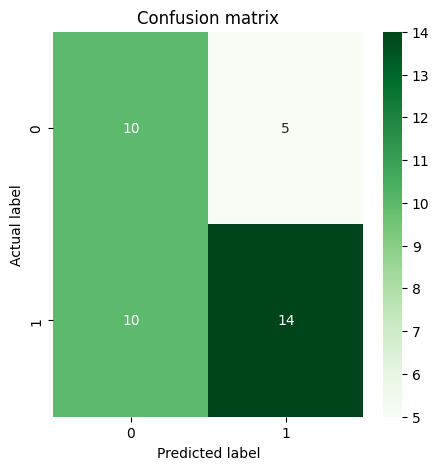

Classification Report:
               precision    recall  f1-score   support

           0       0.50      0.67      0.57        15
           1       0.74      0.58      0.65        24

    accuracy                           0.62        39
   macro avg       0.62      0.62      0.61        39
weighted avg       0.65      0.62      0.62        39



In [374]:
# Train the model
model_nb = GaussianNB() 
model_nb.fit(X_train, y_train)

# Make predictions
predictions_nb = model_nb.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_nb)
print(f"Accuracy of the Naive Bayes model: {accuracy}")

showResults(y_test, predictions_nb, "naive_bayes", column_names, save_logs)

Multi-Layer Perceptron

C:\Users\Catarina\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy of the MLP model: 0.5897435897435898


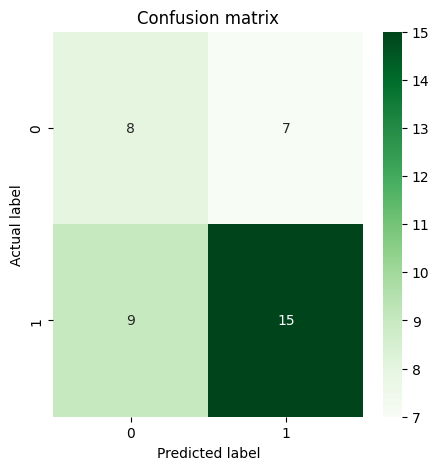

Classification Report:
               precision    recall  f1-score   support

           0       0.47      0.53      0.50        15
           1       0.68      0.62      0.65        24

    accuracy                           0.59        39
   macro avg       0.58      0.58      0.58        39
weighted avg       0.60      0.59      0.59        39



In [375]:
# Train the model
model_mlp = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
model_mlp.fit(X_train, y_train)

# Make predictions
predictions_mlp = model_mlp.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_mlp)
print(f"Accuracy of the MLP model: {accuracy}")

showResults(y_test, predictions_mlp, "mlp", column_names, save_logs)

Decision Tree

Accuracy of the Decision Tree model: 0.5384615384615384


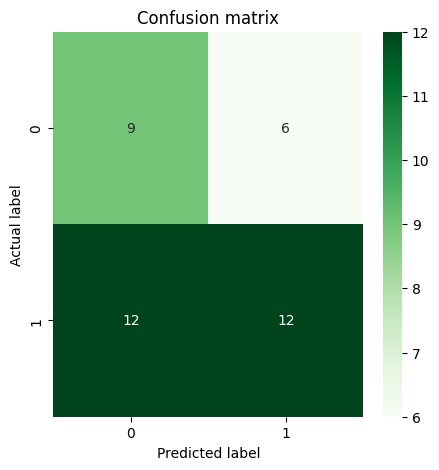

Classification Report:
               precision    recall  f1-score   support

           0       0.43      0.60      0.50        15
           1       0.67      0.50      0.57        24

    accuracy                           0.54        39
   macro avg       0.55      0.55      0.54        39
weighted avg       0.58      0.54      0.54        39



In [376]:
# Train the model
model_dt = DecisionTreeClassifier(random_state=42)  
model_dt.fit(X_train, y_train)

# Make predictions
predictions_dt = model_dt.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_dt)
print(f"Accuracy of the Decision Tree model: {accuracy}")

showResults(y_test, predictions_dt, "decision_tree", column_names, save_logs)

Logistic Regression

Accuracy of the Logistic Regression model: 0.6410256410256411


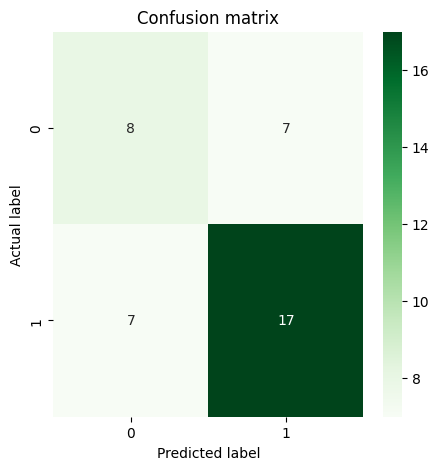

Classification Report:
               precision    recall  f1-score   support

           0       0.53      0.53      0.53        15
           1       0.71      0.71      0.71        24

    accuracy                           0.64        39
   macro avg       0.62      0.62      0.62        39
weighted avg       0.64      0.64      0.64        39



In [377]:
# Train the model
model_lr = LogisticRegression(random_state=42)
model_lr.fit(X_train, y_train)

# Make predictions
predictions_lr = model_lr.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_lr)
print(f"Accuracy of the Logistic Regression model: {accuracy}")

showResults(y_test, predictions_lr, "logistic_regression", column_names, save_logs)

Gradient Boosting Classifier

Accuracy of the Gradient Boosting model: 0.5897435897435898


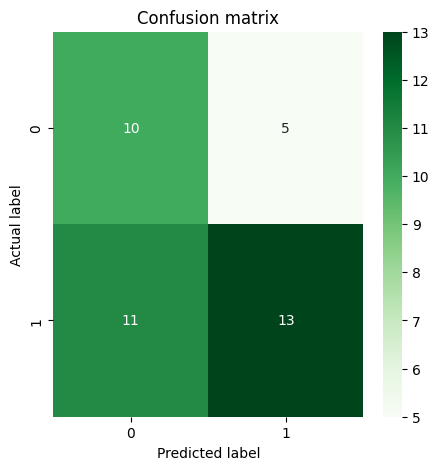

Classification Report:
               precision    recall  f1-score   support

           0       0.48      0.67      0.56        15
           1       0.72      0.54      0.62        24

    accuracy                           0.59        39
   macro avg       0.60      0.60      0.59        39
weighted avg       0.63      0.59      0.59        39



In [378]:
from sklearn.ensemble import GradientBoostingClassifier  

# Train the model
model_gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
model_gb.fit(X_train, y_train)

# Make predictions
predictions_gb = model_gb.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_gb)
print(f"Accuracy of the Gradient Boosting model: {accuracy}")

showResults(y_test, predictions_gb, "gradient_boosting", column_names, save_logs)

Support Vector Machine

Accuracy of the SVM model: 0.6410256410256411


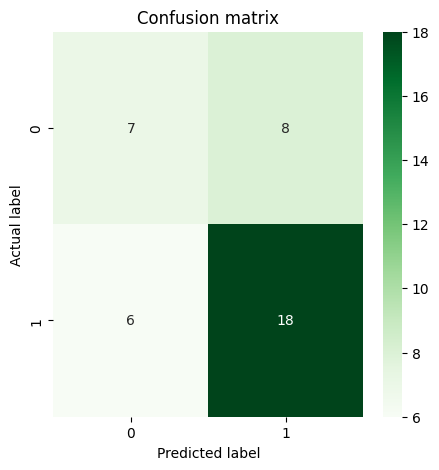

Classification Report:
               precision    recall  f1-score   support

           0       0.54      0.47      0.50        15
           1       0.69      0.75      0.72        24

    accuracy                           0.64        39
   macro avg       0.62      0.61      0.61        39
weighted avg       0.63      0.64      0.64        39



In [379]:
from sklearn.svm import SVC 

# Train the model
model_svm = SVC(random_state=42)
model_svm.fit(X_train, y_train)

# Make predictions
predictions_svm = model_svm.predict(X_test)

# Model performance
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, predictions_svm)
print(f"Accuracy of the SVM model: {accuracy}")

showResults(y_test, predictions_svm, "svm", column_names, save_logs)